# Clustering mass cytometry like FlowSOM

FlowSOM {cite:p}`Van_Gassen_2015` clusters cytometry data in two steps: a self-organising map groups the cells into
a small grid of nodes, typically 10 x 10, and the nodes are then grouped into metaclusters. This tutorial does the same
with fastersom, on the `Levine_32dim` benchmark data set {cite:p}`Levine_2015,Weber_2016`: 265,627 bone marrow cells
from two healthy donors, measured by mass cytometry with 32 surface markers, of which 104,184 cells were assigned to 14
populations by manual gating. We fit the map, group its nodes and compare the result with the gated populations.

Besides fastersom, the tutorial uses [AnnData](https://anndata.readthedocs.io), [scanpy](https://scanpy.readthedocs.io)
with [igraph](https://python.igraph.org) for Leiden clustering, [readfcs](https://github.com/laminlabs/readfcs) to
read the FCS file, and SciPy and scikit-learn, which scanpy installs:

```bash
pip install fastersom scanpy igraph readfcs
```

In [1]:
from pathlib import Path
from urllib.request import urlretrieve

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import readfcs
import scanpy as sc
from scipy.cluster.hierarchy import fcluster, linkage
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

from fastersom import SOM

# the stored outputs were computed on the CPU, which is deterministic; None picks cuda > mps > cpu
DEVICE = "cpu"

## Data

The data comes from the [benchmark-data-Levine-32-dim](https://github.com/lmweber/benchmark-data-Levine-32-dim)
repository (44 MB). Its marker intensities are already transformed with $\operatorname{arcsinh}(x / 5)$, the usual
variance-stabilising transform for mass cytometry, so they can be clustered as they are. The `label` column holds the
gated population of each cell, or NaN for cells that were not assigned to any population.

In [2]:
URL = "https://raw.githubusercontent.com/lmweber/benchmark-data-Levine-32-dim/c6737786dcff3a50145993efed451a2af55e0a00/data/"
data = Path("data")
data.mkdir(exist_ok=True)
for name in ["Levine_32dim.fcs", "population_names_Levine_32dim.txt"]:
    if not (data / name).exists():
        urlretrieve(URL + name, data / name)

fcs = readfcs.read(data / "Levine_32dim.fcs")
fcs.var_names.tolist()

['Time',
 'Cell_length',
 'DNA1',
 'DNA2',
 'CD45RA',
 'CD133',
 'CD19',
 'CD22',
 'CD11b',
 'CD4',
 'CD8',
 'CD34',
 'Flt3',
 'CD20',
 'CXCR4',
 'CD235ab',
 'CD45',
 'CD123',
 'CD321',
 'CD14',
 'CD33',
 'CD47',
 'CD11c',
 'CD7',
 'CD15',
 'CD16',
 'CD44',
 'CD38',
 'CD13',
 'CD3',
 'CD61',
 'CD117',
 'CD49d',
 'HLA-DR',
 'CD64',
 'CD41',
 'Viability',
 'file_number',
 'event_number',
 'label',
 'individual']

Columns 5 to 36 are the 32 markers. We keep them in a new AnnData object, with the gated population and the donor
of each cell in `obs`.

In [3]:
markers = fcs.var_names[4:36]
populations = pd.read_csv(data / "population_names_Levine_32dim.txt", sep="\t", index_col="label")["population"]
populations = populations.str.replace("_", " ")

adata = ad.AnnData(X=fcs[:, markers].X.astype(np.float32), var=pd.DataFrame(index=markers))
labels = pd.Series(fcs[:, "label"].X[:, 0]).map(populations)
adata.obs["population"] = pd.Categorical(labels, categories=populations)
adata.obs["donor"] = pd.Categorical(fcs[:, "individual"].X[:, 0].astype(int).astype(str))
adata

AnnData object with n_obs × n_vars = 265627 × 32
    obs: 'population', 'donor'
    layers: None (.X)

In [4]:
adata.obs["population"].value_counts(dropna=False)

population
NaN                       161443
CD4 T cells                26366
Monocytes                  21099
CD8 T cells                20108
Mature B cells             16520
Pre B cells                 6135
CD16- NK cells              3905
CD34+CD38+CD123- HSPCs      3295
CD16+ NK cells              2248
pDCs                        1238
Basophils                   1207
CD34+CD38lo HSCs             916
Pro B cells                  513
Plasma B cells               330
CD34+CD38+CD123+ HSPCs       304
Name: count, dtype: int64

## Fitting the map

We fit a 10 x 10 map, FlowSOM's default size, on a random subsample of 50,000 cells, and then assign every cell to its
best matching unit (BMU) with `predict`. The map could just as well be fitted on all cells; a subsample keeps this
example light, and fitting on a subsample and mapping all cells is a common pattern for data sets too large to fit at
once.

In [5]:
rng = np.random.default_rng(0)
train = rng.choice(adata.n_obs, 50_000, replace=False)

som = SOM(n_rows=10, n_cols=10, n_epochs=10, random_state=0, device=DEVICE)
%time som.fit(adata.X[train])

adata.obs["som_node"] = som.predict(adata.X)
print(f"quantization error {som.quantization_error(adata.X):.3f}")
print(f"topographic error {som.topographic_error(adata.X):.3f}")

CPU times: user 135 ms, sys: 36.1 ms, total: 171 ms
Wall time: 91.3 ms
quantization error 2.300
topographic error 0.206


`weights_` holds the 100 nodes, one row per node, in the same 32 marker dimensions as the cells. The U-matrix from
`distance_map` shows how far each node is from its grid neighbours: high values mark borders between groups of
similar nodes. The number of cells per node shows how the map distributes them.

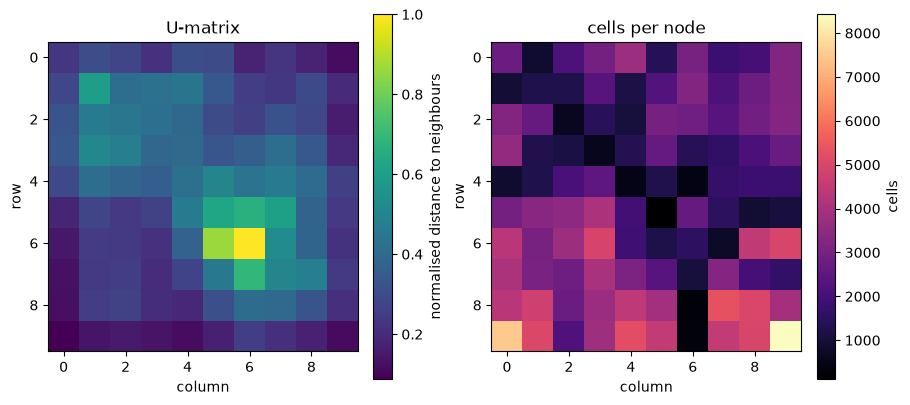

In [6]:
counts = np.bincount(adata.obs["som_node"], minlength=100).reshape(10, 10)

fig, axes = plt.subplots(1, 2, figsize=(9, 4), layout="constrained")
image = axes[0].imshow(som.distance_map(), cmap="viridis")
fig.colorbar(image, ax=axes[0], label="normalised distance to neighbours")
axes[0].set_title("U-matrix")
image = axes[1].imshow(counts, cmap="magma")
fig.colorbar(image, ax=axes[1], label="cells")
axes[1].set_title("cells per node")
for ax in axes:
    ax.set(xlabel="column", ylabel="row")

## Metaclustering the nodes

FlowSOM groups the nodes by consensus hierarchical clustering into a chosen number of metaclusters. Here we use plain
hierarchical clustering with average linkage from SciPy on the node weights, and ask for 20 metaclusters, somewhat more
than the 14 gated populations, as cytometry data usually holds more populations than were gated. Every cell then gets
the metacluster of its node.

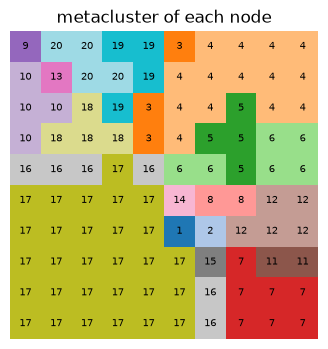

In [7]:
node_metacluster = fcluster(linkage(som.weights_, method="average"), t=20, criterion="maxclust")
adata.obs["metacluster"] = pd.Categorical(node_metacluster[adata.obs["som_node"]])

plt.figure(figsize=(4.5, 4))
plt.imshow(node_metacluster.reshape(10, 10), cmap="tab20")
for node, metacluster in enumerate(node_metacluster):
    plt.text(node % 10, node // 10, metacluster, ha="center", va="center", fontsize=7)
plt.title("metacluster of each node")
plt.axis("off");

The mean marker intensities per metacluster, scaled to 0-1 per marker, show what each metacluster expresses:

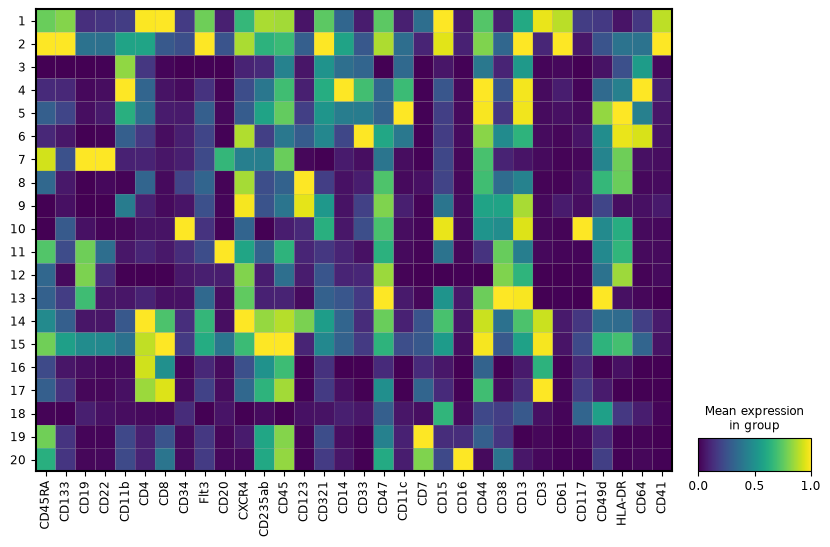

In [8]:
sc.pl.matrixplot(adata, markers, groupby="metacluster", standard_scale="var", figsize=(10, 6))

## Comparison with the gated populations

We compare the metaclusters with the gated populations on the 104,184 cells that have a population. The adjusted Rand
index (ARI) and normalised mutual information (NMI) compare the two partitions as a whole. The F1 score of
each population with the metacluster that matches it best shows how well single populations are recovered, including
small ones. Each population is matched on its own, so two populations can share one metacluster; {cite:t}`Weber_2016`
instead match populations and clusters one to one, which gives lower scores when clusters merge populations.

In [9]:
gated = adata[adata.obs["population"].notna()]


def best_f1(truth, clusters):
    """F1 score of every population with the cluster that matches it best."""
    table = pd.crosstab(truth, clusters)
    precision = table / table.sum(axis=0)
    recall = table.div(table.sum(axis=1), axis=0)
    return (2 * precision * recall / (precision + recall)).fillna(0).max(axis=1)


truth, metaclusters = gated.obs["population"], gated.obs["metacluster"]
print(f"ARI {adjusted_rand_score(truth, metaclusters):.3f}")
print(f"NMI {normalized_mutual_info_score(truth, metaclusters):.3f}")
f1 = best_f1(truth, metaclusters)
f1.to_frame("F1").assign(cells=truth.value_counts()).sort_values("cells", ascending=False).round(3)

ARI 0.637
NMI 0.802


,F1,cells
population,,
CD4 T cells,0.708,26366
Monocytes,0.857,21099
CD8 T cells,0.606,20108
Mature B cells,0.987,16520
Pre B cells,0.830,6135
CD16- NK cells,0.865,3905
CD34+CD38+CD123- HSPCs,0.818,3295
CD16+ NK cells,0.808,2248
pDCs,0.859,1238


Most populations, among them the mature and pre B cells, monocytes, NK cells and basophils, are matched by a metacluster with
an F1 score above 0.8. The CD4 and CD8 T cells share one metacluster, and the smallest populations, such as the
pro B cells and two of the CD34+ progenitor subsets with a few hundred to a thousand cells each, have few nodes of
their own on a 10 x 10 map and share metaclusters with related populations. The fraction of each population in each metacluster shows which populations were split or
merged:

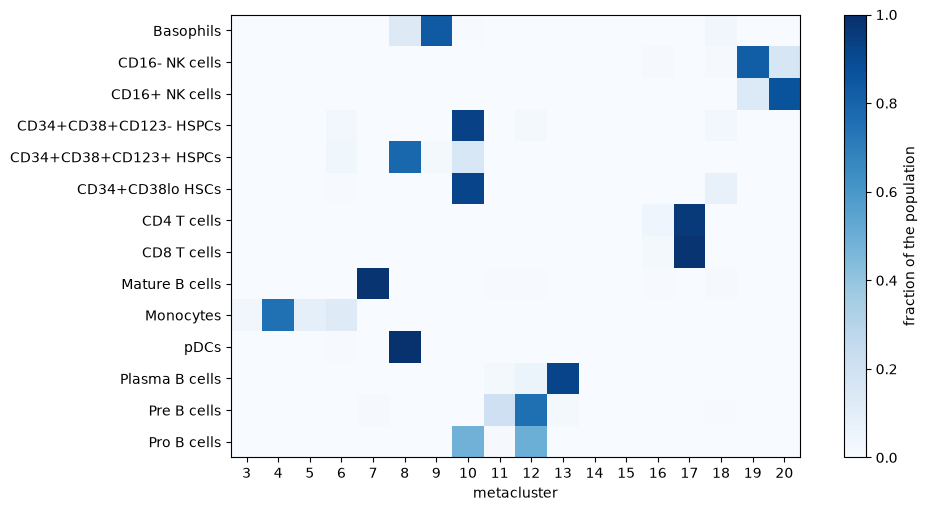

In [10]:
fractions = pd.crosstab(truth, metaclusters, normalize="index")

fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
image = ax.imshow(fractions, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(fractions.shape[1]), fractions.columns)
ax.set_yticks(range(fractions.shape[0]), fractions.index)
ax.set_xlabel("metacluster")
fig.colorbar(image, label="fraction of the population");

### How many metaclusters?

The number of metaclusters is chosen in advance, and the agreement with the gated populations depends on it, though
not in a simple way, as every number cuts the tree of nodes at a different place:

In [11]:
rows = []
for k in (10, 14, 20, 30, 40):
    clusters = fcluster(linkage(som.weights_, method="average"), t=k, criterion="maxclust")[gated.obs["som_node"]]
    ari, mean_f1 = adjusted_rand_score(truth, clusters), best_f1(truth, clusters).mean()
    rows.append({"metaclusters": k, "ARI": ari, "mean F1": mean_f1})
pd.DataFrame(rows).set_index("metaclusters").round(3)

,ARI,mean F1
metaclusters,,
10,0.705,0.593
14,0.654,0.634
20,0.637,0.693
30,0.847,0.751
40,0.640,0.702


### Leiden clustering of the nodes

Instead of hierarchical clustering, the nodes can be clustered like cells in scanpy: as an AnnData object with one
observation per node, a k-nearest-neighbour graph and Leiden community detection {cite:p}`Traag_2019`. The resolution
then takes the place of the number of metaclusters.

In [12]:
nodes = ad.AnnData(som.weights_, var=pd.DataFrame(index=markers))
sc.pp.neighbors(nodes, n_neighbors=10, use_rep="X", random_state=0)

rows = []
for resolution in (0.5, 1.0, 2.0, 4.0):
    sc.tl.leiden(nodes, resolution=resolution, flavor="igraph", n_iterations=2, directed=False, random_state=0)
    clusters = nodes.obs["leiden"].to_numpy()[gated.obs["som_node"]]
    rows.append(
        {
            "resolution": resolution,
            "clusters": nodes.obs["leiden"].nunique(),
            "ARI": adjusted_rand_score(truth, clusters),
            "mean F1": best_f1(truth, clusters).mean(),
        }
    )
pd.DataFrame(rows).set_index("resolution").round(3)

,clusters,ARI,mean F1
resolution,,,
0.5,6,0.926,0.488
1.0,7,0.903,0.480
2.0,10,0.772,0.501
4.0,17,0.593,0.561


A few large clusters agree well with the large populations, which dominate the ARI, but merge the small ones,
which lowers the mean F1 score; higher resolutions separate more of them.

## Next steps

- On a GPU the same code fits all 265,627 cells in a fraction of a second; set `DEVICE = None` (see
  [](../guide/devices.md)).
- Larger maps resolve smaller populations, at the cost of more nodes to group (see [](../guide/map-size.md)).
- The SOM and the metaclusters are stored in `adata.obs`, so the usual scanpy tools apply, for example
  `sc.tl.rank_genes_groups(adata, "metacluster")` to find the markers that distinguish the metaclusters.